# Advanced Image Processing — Oxford-IIIT Pet Segmentation
### A controlled comparison of two U-Net models

**Objective.** Train two lightweight U-Net segmentation models on the Oxford-IIIT Pet dataset, compare their performance using intersection over union (IoU) and the Dice coefficient, and inspect qualitative predictions on previously unseen test images.

**Experimental design.** Both models have the same architecture, training data, loss, optimizer and training budget. The random seed changes from **42** to **123**. The official `trainval` images are divided into training and validation subsets; the **official `test` split is kept separate** until the final evaluation.

**DETAILS.** This notebook contains data preparation, a U-Net implementation, reproducible training and test functions, full-test-set IoU/Dice tables, training curves, per-class measurements, and six visual comparisons from three different pet breeds. Results are calculated by the code after the notebook runs; no scores have been inserted manually.

**How to run.** Open this `.ipynb` file in Google Colab, choose **Runtime → Change runtime type → T4 GPU** (or another GPU), and select **Runtime → Run all** A GPU is recommended to run this experiment


## 1. Imports and experiment settings

The model treats the segmentation task as **three-class semantic segmentation**. The original trimap pixel values are `1 = foreground (pet)`, `2 = background`, and `3 = boundary/uncertain region`. For PyTorch's multiclass cross-entropy loss, the values are remapped to `0`, `1`, and `2` respectively. Breed categories are used to select diverse qualitative examples; they are not segmentation classes.

All numbers in the final table are computed from predictions, not hard-coded. The image resolution and training budget were chosen to be practical on a standard Colab GPU while still giving the models enough capacity to learn useful boundaries.

In [ ]:
# PyTorch, torchvision, NumPy, pandas, matplotlib and Pillow are included.
import os
import sys
import json
import random
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import OxfordIIITPet
from torchvision import transforms as T
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

# Work in a single location so that every output is easy to locate.
DATA_ROOT = Path('data')
OUTPUT_DIR = Path('pet_segmentation_results')
DATA_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 192
BATCH_SIZE = 12
NUM_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 6
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
BASE_CHANNELS = 24
VALIDATION_FRACTION = 0.10
SPLIT_SEED = 2026
MODEL_SEEDS = (42, 123)
NUM_CLASSES = 3
CLASS_NAMES = ('Foreground (pet)', 'Background', 'Boundary')
NUM_WORKERS = 2 if sys.platform != 'win32' else 0
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'

print('PyTorch:', torch.__version__)
print('torchvision:', __import__('torchvision').__version__)
print('Device:', DEVICE, '| Mixed precision:', USE_AMP)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('In this my work, A GPU is recommended. CPU training is possible but much slower.')

PyTorch: 2.14.1+cu130
torchvision: 0.29.1+cu130
Device: cuda | Mixed precision: True
GPU: Tesla T4


In [ ]:
# Resetting these generators makes the two experiments reproducible in one notebook run.
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def seed_worker(worker_id: int) -> None:
    # Each data-loader worker receives its own reproducible augmentation RNG.
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


set_seed(SPLIT_SEED)

## 2. Download the data and create the train/validation/test splits

`torchvision.datasets.OxfordIIITPet` supplies the original photographs, breed labels and pixel-level trimaps. The provided `trainval` and `test` subsets are respected. Only `trainval` is subdivided; its validation subset is stratified by breed so that rare categories are not accidentally excluded. Exactly the same split is used for both U-Net models.

In [ ]:
# I downloaded once. torchvision reused the extracted files on subsequent runs.
trainval_base = OxfordIIITPet(
    root=str(DATA_ROOT), split='trainval',
    target_types=('category', 'segmentation'), download=True
)
test_base = OxfordIIITPet(
    root=str(DATA_ROOT), split='test',
    target_types=('category', 'segmentation'), download=False
)

# The official split text files align with the order returned by torchvision.
annotation_dir = DATA_ROOT / 'oxford-iiit-pet' / 'annotations'

def read_split_file(split_name: str):
    lines = (annotation_dir / f'{split_name}.txt').read_text().splitlines()
    image_ids = [line.split()[0] for line in lines if line.strip()]
    breed_labels = np.array(
        [int(line.split()[1]) - 1 for line in lines if line.strip()],
        dtype=np.int64
    )
    return image_ids, breed_labels

trainval_ids, trainval_labels = read_split_file('trainval')
test_ids, test_labels = read_split_file('test')
assert len(trainval_base) == len(trainval_labels)
assert len(test_base) == len(test_labels)
assert trainval_base.classes == test_base.classes

# A fixed, class-stratified validation set: ~10% of each breed's trainval images.
rng = np.random.default_rng(SPLIT_SEED)
train_indices, val_indices = [], []
for breed_id in np.unique(trainval_labels):
    indices = np.flatnonzero(trainval_labels == breed_id)
    rng.shuffle(indices)
    n_val = max(1, round(len(indices) * VALIDATION_FRACTION))
    val_indices.extend(indices[:n_val].tolist())
    train_indices.extend(indices[n_val:].tolist())

rng.shuffle(train_indices)
rng.shuffle(val_indices)
assert not (set(train_indices) & set(val_indices))
assert len(train_indices) + len(val_indices) == len(trainval_base)

print('Training images:', len(train_indices))
print('Validation images:', len(val_indices))
print('Official test images:', len(test_base))
print('Number of pet breeds:', len(trainval_base.classes))
print('No test images are included in training or validation.')

100%|██████████| 792M/792M [00:44<00:00, 17.9MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 9.23MB/s]


Training images: 3311
Validation images: 369
Official test images: 3669
Number of pet breeds: 37
No test images are included in training or validation.


## 3. Preprocessing and data loaders

Each photograph is resized with **bilinear interpolation**, while its integer segmentation mask uses **nearest-neighbour interpolation** to avoid creating invalid intermediate class labels. Horizontal flipping is applied jointly to an image and its mask during training; mild colour jitter affects only the image. Validation and test images are never augmented. The image tensors are normalized using fixed RGB mean and standard deviation values.

In [ ]:
# A small dataset wrapper keeps paired image/mask operations in one place.
class PetSegmentationDataset(Dataset):
    def __init__(self, base_dataset, indices=None, training=False):
        self.base = base_dataset
        self.indices = list(range(len(base_dataset))) if indices is None else list(indices)
        self.training = training
        self.jitter = T.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.10)
        self.normalize = T.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225)
        )

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        original_index = self.indices[item]
        image, (breed_id, mask) = self.base[original_index]

        # Resize the image smoothly, but preserve the discrete segmentation labels.
        image = image.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)
        mask = mask.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.NEAREST)

        if self.training:
            if random.random() < 0.5:
                image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
                mask = mask.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            image = self.jitter(image)

        # Segmentation masks are class IDs, not grayscale intensities in [0, 1].
        mask_array = np.asarray(mask, dtype=np.uint8)
        if not np.isin(mask_array, (1, 2, 3)).all():
            raise ValueError(f'Unexpected trimap label(s): {np.unique(mask_array)}')
        mask_tensor = torch.from_numpy(mask_array.astype(np.int64) - 1)

        rgb_array = np.asarray(image, dtype=np.uint8).copy()
        image_tensor = torch.from_numpy(rgb_array).permute(2, 0, 1).float() / 255.0
        image_tensor = self.normalize(image_tensor)
        return image_tensor, mask_tensor, int(breed_id)


train_data = PetSegmentationDataset(trainval_base, train_indices, training=True)
val_data = PetSegmentationDataset(trainval_base, val_indices, training=False)
test_data = PetSegmentationDataset(test_base, training=False)


def make_train_loader(seed):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        train_data, batch_size=BATCH_SIZE, shuffle=True,
        generator=generator, num_workers=NUM_WORKERS,
        worker_init_fn=seed_worker, pin_memory=USE_AMP,
        persistent_workers=(NUM_WORKERS > 0)
    )


def make_eval_loader(dataset):
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=USE_AMP,
        persistent_workers=(NUM_WORKERS > 0)
    )


val_loader = make_eval_loader(val_data)
test_loader = make_eval_loader(test_data)

# A quick preflight check catches invalid masks or a wrongly shaped input early.
example_image, example_mask, example_breed = test_data[0]
assert example_image.shape == (3, IMAGE_SIZE, IMAGE_SIZE)
assert example_mask.shape == (IMAGE_SIZE, IMAGE_SIZE)
assert example_mask.dtype == torch.long
assert set(torch.unique(example_mask).tolist()).issubset({0, 1, 2})
print('Image shape:', tuple(example_image.shape))
print('Mask shape:', tuple(example_mask.shape))
print('Mask labels after remapping:', torch.unique(example_mask).tolist())
print('Example breed:', test_base.classes[example_breed])

Image shape: (3, 192, 192)
Mask shape: (192, 192)
Mask labels after remapping: [0, 1, 2]
Example breed: Abyssinian


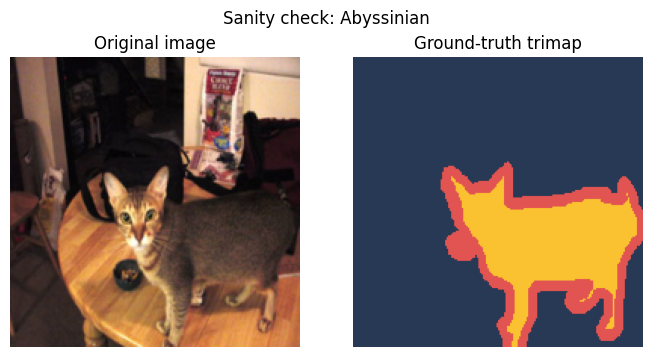

In [ ]:
# Visualize one unaugmented example and confirm that the masks are class-valued.
RGB_MEAN = np.array((0.485, 0.456, 0.406), dtype=np.float32)
RGB_STD = np.array((0.229, 0.224, 0.225), dtype=np.float32)
MASK_COLORS = np.array([
    [250, 193, 48],    # foreground: gold
    [39, 57, 84],      # background: dark blue
    [226, 84, 81]      # boundary: coral red
], dtype=np.uint8)


def image_for_display(x):
    # Undo the fixed RGB normalization to recover a viewable image.
    rgb = x.detach().cpu().permute(1, 2, 0).numpy()
    return np.clip(rgb * RGB_STD + RGB_MEAN, 0, 1)


def mask_for_display(mask):
    return MASK_COLORS[np.asarray(mask, dtype=np.uint8)]


fig, axes = plt.subplots(1, 2, figsize=(7, 3.6))
axes[0].imshow(image_for_display(example_image))
axes[0].set_title('Original image')
axes[1].imshow(mask_for_display(example_mask))
axes[1].set_title('Ground-truth trimap')
for ax in axes:
    ax.axis('off')
fig.suptitle(f'Sanity check: {test_base.classes[example_breed]}')
plt.tight_layout()
plt.show()

## 4. A compact U-Net architecture

The encoder extracts spatial features through repeated `3 × 3` convolutions and downsampling. The decoder upsamples the deep features and combines them with higher-resolution encoder features through **skip connections**. The final `1 × 1` convolution returns three logits per pixel. The model is built from scratch and is not pretrained; this makes the seed-based comparison meaningful.

In [ ]:
# Each block uses two convolutions to learn spatial context at its resolution.
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class UpBlock(nn.Module):
    def __init__(self, deep_channels, skip_channels, out_channels):
        super().__init__()
        self.conv = DoubleConv(deep_channels + skip_channels, out_channels)

    def forward(self, deep_features, skip_features):
        # Explicitly match the skip-connection size, including for odd image shapes.
        x = F.interpolate(
            deep_features, size=skip_features.shape[-2:],
            mode='bilinear', align_corners=False
        )
        return self.conv(torch.cat([skip_features, x], dim=1))


class SimpleUNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=3, base_channels=24):
        super().__init__()
        c = base_channels
        self.enc1 = DoubleConv(in_channels, c)
        self.enc2 = DoubleConv(c, c * 2)
        self.enc3 = DoubleConv(c * 2, c * 4)
        self.enc4 = DoubleConv(c * 4, c * 8)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(c * 8, c * 16)
        self.up4 = UpBlock(c * 16, c * 8, c * 8)
        self.up3 = UpBlock(c * 8, c * 4, c * 4)
        self.up2 = UpBlock(c * 4, c * 2, c * 2)
        self.up1 = UpBlock(c * 2, c, c)
        self.classifier = nn.Conv2d(c, num_classes, kernel_size=1)

    def forward(self, x):
        s1 = self.enc1(x)
        s2 = self.enc2(self.pool(s1))
        s3 = self.enc3(self.pool(s2))
        s4 = self.enc4(self.pool(s3))
        x = self.bottleneck(self.pool(s4))
        x = self.up4(x, s4)
        x = self.up3(x, s3)
        x = self.up2(x, s2)
        x = self.up1(x, s1)
        return self.classifier(x)


# A single tensor verifies that the model returns pixel-wise class logits.
probe_model = SimpleUNet(base_channels=BASE_CHANNELS)
with torch.no_grad():
    probe_logits = probe_model(torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE))
assert probe_logits.shape == (1, NUM_CLASSES, IMAGE_SIZE, IMAGE_SIZE)
print('Output shape:', tuple(probe_logits.shape))
print('Trainable parameters:', f'{sum(p.numel() for p in probe_model.parameters()):,}')
del probe_model, probe_logits

Output shape: (1, 3, 192, 192)
Trainable parameters: 4,416,723


## 5. Loss function and evaluation metrics

The training objective combines **cross-entropy**, which encourages correct pixel classes, with a **soft Dice loss**, which rewards overlap even when classes have different frequencies. The reporting metrics, by contrast, use **hard predictions** from `argmax`.

For class $c$, let $TP$, $FP$, and $FN$ denote true positives, false positives, and false negatives. The definitions are:

$$
\mathrm{IoU}_c = \frac{TP_c}{TP_c+FP_c+FN_c}, \qquad
\mathrm{Dice}_c = \frac{2TP_c}{2TP_c+FP_c+FN_c}.
$$

I sum the three-class confusion matrix over **every pixel of every official test image**, calculate an IoU and Dice score for each class, and then report the **unweighted macro-average across all three classes**. This prevents the common background class from dominating the reported score. Foreground-only scores and per-image scores are also saved for transparency. For an individual image, classes absent from both the prediction and target are omitted from that image's macro-average; this does not affect the full-dataset macro score.

In [ ]:
# Cross-entropy and soft Dice are averaged with equal weights for training.
class CrossEntropyDiceLoss(nn.Module):
    def forward(self, logits, labels):
        cross_entropy = F.cross_entropy(logits, labels)
        probabilities = F.softmax(logits.float(), dim=1)
        targets_one_hot = F.one_hot(labels, num_classes=NUM_CLASSES)
        targets_one_hot = targets_one_hot.permute(0, 3, 1, 2).float()
        spatial_dims = (0, 2, 3)
        intersection = (probabilities * targets_one_hot).sum(dim=spatial_dims)
        denominator = (probabilities + targets_one_hot).sum(dim=spatial_dims)
        soft_dice = (2.0 * intersection + 1e-6) / (denominator + 1e-6)
        dice_loss = 1.0 - soft_dice.mean()
        return 0.5 * cross_entropy + 0.5 * dice_loss


def scores_from_confusion_matrix(confusion):
    # Rows are true labels, columns are predicted labels.
    cm = np.asarray(confusion, dtype=np.float64)
    tp = np.diag(cm)
    ground_truth = cm.sum(axis=1)
    predicted = cm.sum(axis=0)
    union = ground_truth + predicted - tp
    dice_denom = ground_truth + predicted

    iou = np.divide(tp, union, out=np.full(NUM_CLASSES, np.nan), where=union > 0)
    dice = np.divide(2 * tp, dice_denom,
                     out=np.full(NUM_CLASSES, np.nan), where=dice_denom > 0)
    return {
        'iou_per_class': iou,
        'dice_per_class': dice,
        'macro_iou': float(np.nanmean(iou)),
        'macro_dice': float(np.nanmean(dice)),
        'support_pixels': ground_truth.astype(np.int64),
    }


# Metric unit test: perfect segmentation must achieve 1.0 for every class.
perfect_matrix = np.diag([10, 20, 30])
perfect_scores = scores_from_confusion_matrix(perfect_matrix)
assert np.isclose(perfect_scores['macro_iou'], 1.0)
assert np.isclose(perfect_scores['macro_dice'], 1.0)
assert np.allclose(perfect_scores['iou_per_class'], 1.0)
print('Metric sanity check passed: perfect predictions have IoU = Dice = 1.')

Metric sanity check passed: perfect predictions have IoU = Dice = 1.


## 6. Training, validation, and test functions

The training function applies backpropagation only to the training subset. Validation uses inference mode and no gradient updates. **Model selection uses validation macro-IoU only:** the best checkpoint for each seed is saved with early stopping if the validation score has not improved for six epochs. The test set is not used to choose checkpoints, epochs or hyperparameters.

In [ ]:
# Training is isolated from evaluation, so test images can never update model weights.
def train_one_epoch(model, loader, optimizer, loss_function, scaler):
    model.train()
    total_loss, total_images = 0.0, 0
    for images, labels, _ in tqdm(loader, desc='Train', leave=False):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(images)
            loss = loss_function(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * images.size(0)
        total_images += images.size(0)
    return total_loss / total_images


@torch.inference_mode()
def evaluate_model(model, loader, loss_function=None, image_ids=None):
    """Evaluate all samples; optionally retain one record per image."""
    model.eval()
    confusion = torch.zeros((NUM_CLASSES, NUM_CLASSES), dtype=torch.int64)
    total_loss, total_images = 0.0, 0
    image_records = []

    for images, labels, _ in tqdm(loader, desc='Evaluate', leave=False):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(images)
            loss = loss_function(logits, labels) if loss_function is not None else None
        predictions = logits.argmax(dim=1)

        encoded = labels.reshape(-1) * NUM_CLASSES + predictions.reshape(-1)
        batch_confusion = torch.bincount(
            encoded.long(), minlength=NUM_CLASSES ** 2
        ).reshape(NUM_CLASSES, NUM_CLASSES)
        confusion += batch_confusion.cpu()
        if loss is not None:
            total_loss += loss.item() * images.size(0)

        # For the final test pass, also save every individual image's scores.
        if image_ids is not None:
            true_np = labels.cpu().numpy()
            pred_np = predictions.cpu().numpy()
            for j in range(images.size(0)):
                sample_confusion = np.bincount(
                    (true_np[j] * NUM_CLASSES + pred_np[j]).ravel(),
                    minlength=NUM_CLASSES ** 2
                ).reshape(NUM_CLASSES, NUM_CLASSES)
                sample_scores = scores_from_confusion_matrix(sample_confusion)
                image_records.append({
                    'image_id': image_ids[total_images + j],
                    'IoU': sample_scores['macro_iou'],
                    'DICE': sample_scores['macro_dice'],
                    'foreground_IoU': sample_scores['iou_per_class'][0],
                    'foreground_DICE': sample_scores['dice_per_class'][0],
                })
        total_images += images.size(0)

    metrics = scores_from_confusion_matrix(confusion.numpy())
    metrics['confusion_matrix'] = confusion.numpy()
    metrics['num_images'] = total_images
    metrics['loss'] = total_loss / total_images if loss_function is not None else np.nan
    if image_ids is not None:
        assert len(image_records) == len(image_ids) == total_images
    return metrics, image_records


def test_model(model, loader, image_ids):
    # This dedicated test function is called once per finished model.
    return evaluate_model(model, loader, loss_function=None, image_ids=image_ids)


def fit_model(seed):
    set_seed(seed)
    model = SimpleUNet(num_classes=NUM_CLASSES, base_channels=BASE_CHANNELS).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=NUM_EPOCHS, eta_min=1e-5
    )
    loss_function = CrossEntropyDiceLoss()
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    train_loader = make_train_loader(seed)

    best_iou = -1.0
    epochs_without_gain = 0
    history = []
    checkpoint = OUTPUT_DIR / f'unet_seed_{seed}_best.pt'

    for epoch in range(1, NUM_EPOCHS + 1):
        print(f'\nSeed {seed} | Epoch {epoch:02d}/{NUM_EPOCHS}')
        train_loss = train_one_epoch(model, train_loader, optimizer, loss_function, scaler)
        val_metrics, _ = evaluate_model(model, val_loader, loss_function)
        scheduler.step()

        history.append({
            'seed': seed, 'epoch': epoch,
            'train_loss': train_loss, 'val_loss': val_metrics['loss'],
            'val_iou': val_metrics['macro_iou'],
            'val_dice': val_metrics['macro_dice'],
        })
        print(
            f'Train loss={train_loss:.4f} | Val loss={val_metrics["loss"]:.4f} | '
            f'Val macro-IoU={val_metrics["macro_iou"]:.4f} | '
            f'Val macro-Dice={val_metrics["macro_dice"]:.4f}'
        )

        # Keep the checkpoint that actually performed best on validation data.
        if val_metrics['macro_iou'] > best_iou + 1e-4:
            best_iou = val_metrics['macro_iou']
            epochs_without_gain = 0
            torch.save({
                'state_dict': model.state_dict(),
                'seed': seed, 'epoch': epoch,
                'best_val_macro_iou': best_iou,
                'image_size': IMAGE_SIZE,
                'num_classes': NUM_CLASSES,
            }, checkpoint)
        else:
            epochs_without_gain += 1
            if epochs_without_gain >= EARLY_STOPPING_PATIENCE:
                print('Early stopping: validation macro-IoU has stopped improving.')
                break

    # Reload exactly the best validation checkpoint before any test evaluation.
    selected = torch.load(checkpoint, map_location=DEVICE, weights_only=True)
    model.load_state_dict(selected['state_dict'])
    print(f'Best epoch for seed {seed}: {selected["epoch"]} '
          f'(validation IoU={selected["best_val_macro_iou"]:.4f})')
    return model, pd.DataFrame(history), selected

## 7. Train both models

I ran the following cell to train **two independent U-Nets**. It was intentionally not a demonstration with untrained models: both networks were optimized on the training set and their best weights were restored. I used a standard GPU runtime because this was the longest step when First tried it with CPU, I chnaged the runtime and used my T4 GPU..

In [ ]:
# Only the random seed differs between the two controlled training runs.
models = {}
histories = {}
checkpoints = {}

for model_number, model_seed in enumerate(MODEL_SEEDS, start=1):
    print('\n' + '=' * 62)
    print(f'TRAINING U-Net {model_number} | random seed {model_seed}')
    print('=' * 62)
    trained_model, history_frame, checkpoint_info = fit_model(model_seed)
    models[model_seed] = trained_model
    histories[model_seed] = history_frame
    checkpoints[model_seed] = checkpoint_info

all_history = pd.concat(histories.values(), ignore_index=True)
all_history.to_csv(OUTPUT_DIR / 'training_history.csv', index=False)
print('\nBoth U-Net models are trained and their checkpoints are saved.')


TRAINING U-Net 1 | random seed 42

Seed 42 | Epoch 01/20


Train:   0%|          | 0/276 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/31 [00:00<?, ?it/s]

Train loss=0.6026 | Val loss=0.4642 | Val macro-IoU=0.5539 | Val macro-Dice=0.6868

Seed 42 | Epoch 02/20


Train:   0%|          | 0/276 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/31 [00:00<?, ?it/s]

... (112 outputs left out)

Train loss=0.1771 | Val loss=0.2221 | Val macro-IoU=0.7493 | Val macro-Dice=0.8453

Seed 123 | Epoch 20/20


Train:   0%|          | 0/276 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/31 [00:00<?, ?it/s]

Train loss=0.1755 | Val loss=0.2229 | Val macro-IoU=0.7485 | Val macro-Dice=0.8448
Best epoch for seed 123: 19 (validation IoU=0.7493)

Both U-Net models are trained and their checkpoints are saved.


## 8. Compare learning curves

The training-loss and validation-loss curves help identify convergence and overfitting. Validation macro-IoU is the actual checkpoint-selection metric. Comparing both runs shows how much a change of initialization and stochastic training order affected the learning process.

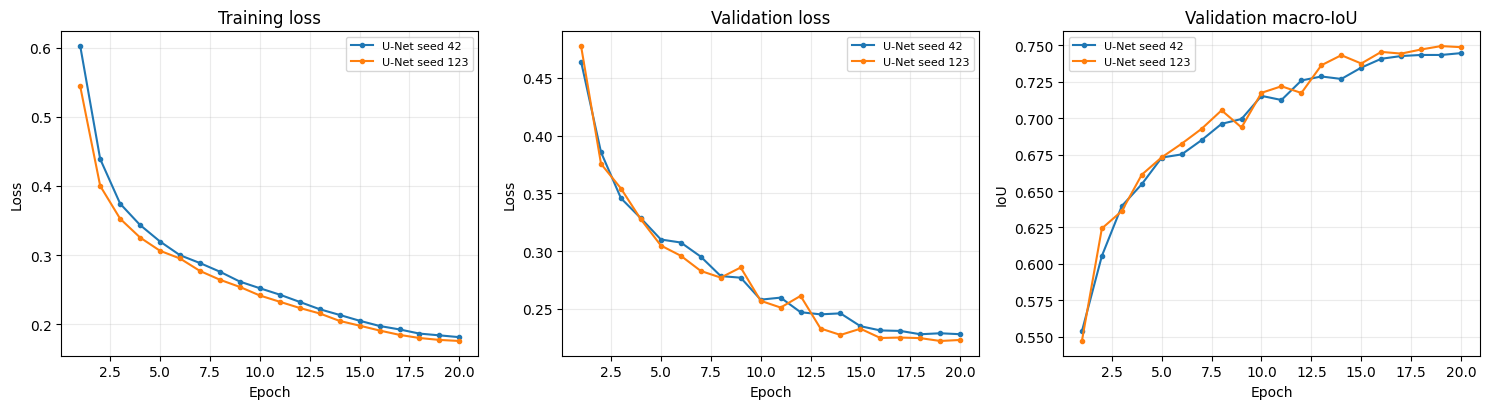

In [ ]:
# Curves are created from real epoch-by-epoch measurements, not example values.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
series_to_plot = [
    ('train_loss', 'Training loss', 'Loss'),
    ('val_loss', 'Validation loss', 'Loss'),
    ('val_iou', 'Validation macro-IoU', 'IoU'),
]
for seed in MODEL_SEEDS:
    history = histories[seed]
    for ax, (key, title, ylabel) in zip(axes, series_to_plot):
        ax.plot(history['epoch'], history[key], marker='o', markersize=3,
                label=f'U-Net seed {seed}')
        ax.set_title(title)
        ax.set_xlabel('Epoch')
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.25)
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=160, bbox_inches='tight')
plt.show()

## 9. Evaluate the entire official test set

Both restored checkpoints now predict the same **unseen official test images**. The confusion matrix accumulates all test pixels across every batch, so the final IoU and Dice scores are genuinely full-test-set results. The test loop also exports one row for **each individual test image** and each model.

In [ ]:
# Test predictions are computed with inference mode and no parameter updates.
test_scores = {}
per_image_frames = []

for model_number, seed in enumerate(MODEL_SEEDS, start=1):
    print(f'Evaluating U-Net {model_number} (seed {seed}) on {len(test_data)} test images...')
    scores, image_rows = test_model(models[seed], test_loader, test_ids)
    assert scores['num_images'] == len(test_data)
    test_scores[seed] = scores
    image_frame = pd.DataFrame(image_rows)
    image_frame.insert(0, 'Model', f'U-Net {model_number}')
    image_frame.insert(1, 'Seed', seed)
    per_image_frames.append(image_frame)

per_image_results = pd.concat(per_image_frames, ignore_index=True)
per_image_results.to_csv(OUTPUT_DIR / 'per_test_image_metrics.csv', index=False)
assert len(per_image_results) == len(test_data) * len(MODEL_SEEDS)
print('Test evaluation completed for every official test sample and both models.')

Evaluating U-Net 1 (seed 42) on 3669 test images...


Evaluate:   0%|          | 0/306 [00:00<?, ?it/s]

Evaluating U-Net 2 (seed 123) on 3669 test images...


Evaluate:   0%|          | 0/306 [00:00<?, ?it/s]

Test evaluation completed for every official test sample and both models.


In [ ]:
# This is the assignment's requested final table. Values are on the [0, 1] scale.
comparison_rows = []
for model_number, seed in enumerate(MODEL_SEEDS, start=1):
    results = test_scores[seed]
    comparison_rows.append({
        'Model': f'U-Net {model_number}',
        'IOU': results['macro_iou'],
        'DICE': results['macro_dice'],
    })

comparison = pd.DataFrame(comparison_rows)
print('FINAL RESULTS — ALL OFFICIAL TEST IMAGES')
display(comparison.style.format({'IOU': '{:.4f}', 'DICE': '{:.4f}'}))
comparison.to_csv(OUTPUT_DIR / 'final_model_comparison.csv', index=False)

# Optional detail: performance for each of the three semantic classes.
class_rows = []
for model_number, seed in enumerate(MODEL_SEEDS, start=1):
    results = test_scores[seed]
    for class_id, name in enumerate(CLASS_NAMES):
        class_rows.append({
            'Model': f'U-Net {model_number}',
            'Class': name,
            'IOU': results['iou_per_class'][class_id],
            'DICE': results['dice_per_class'][class_id],
            'Ground-truth pixels': results['support_pixels'][class_id],
        })

per_class_comparison = pd.DataFrame(class_rows)
print('\nPER-CLASS IOU / DICE ON THE ENTIRE TEST SET')
display(per_class_comparison.style.format({'IOU': '{:.4f}', 'DICE': '{:.4f}'}))
per_class_comparison.to_csv(OUTPUT_DIR / 'per_class_test_metrics.csv', index=False)

FINAL RESULTS — ALL OFFICIAL TEST IMAGES


,Model,IOU,DICE
0,U-Net 1,0.7579,0.8524
1,U-Net 2,0.7628,0.8557



PER-CLASS IOU / DICE ON THE ENTIRE TEST SET


,Model,Class,IOU,DICE,Ground-truth pixels
0,U-Net 1,Foreground (pet),0.8286,0.9063,40565142
1,U-Net 1,Background,0.9073,0.9514,78067393
2,U-Net 1,Boundary,0.5377,0.6994,16621481
3,U-Net 2,Foreground (pet),0.8340,0.9095,40565142
4,U-Net 2,Background,0.9112,0.9535,78067393
5,U-Net 2,Boundary,0.5432,0.7040,16621481


## 10. Qualitative test results: three breeds, two samples each

The six images below are taken from **three different breed categories** in the official test set: **Abyssinian, Pug and Samoyed**. Each row shows the input image, its annotated trimap, and predictions from both independently trained U-Nets. The same test images are shown for both models to make the comparison fair. Within each predicted-mask title, IoU is the three-class macro score for that single image.

The segmentation labels are also visually distinguishable: gold is pet foreground, dark blue is background, and coral red is the boundary. Thus the figure displays all **three segmentation classes**, in addition to covering three different breed categories.

In [ ]:
# Select two fixed test examples from each breed, without choosing 'easy' predictions.
requested_breeds = ['Abyssinian', 'Pug', 'Samoyed']
selected_examples = []
for breed in requested_breeds:
    breed_id = test_base.class_to_idx[breed]
    matches = np.flatnonzero(test_labels == breed_id)
    assert len(matches) >= 2, f'Not enough test images for {breed}'
    selected_examples.extend([(int(i), breed) for i in matches[:2]])

assert len(selected_examples) == 6
assert len({breed for _, breed in selected_examples}) == 3
print('Qualitative evaluation images:')
for index, breed in selected_examples:
    print(f'  {breed:12s}: {test_ids[index]}')

Qualitative evaluation images:
  Abyssinian  : Abyssinian_201
  Abyssinian  : Abyssinian_202
  Pug         : pug_193
  Pug         : pug_194
  Samoyed     : samoyed_191
  Samoyed     : samoyed_192


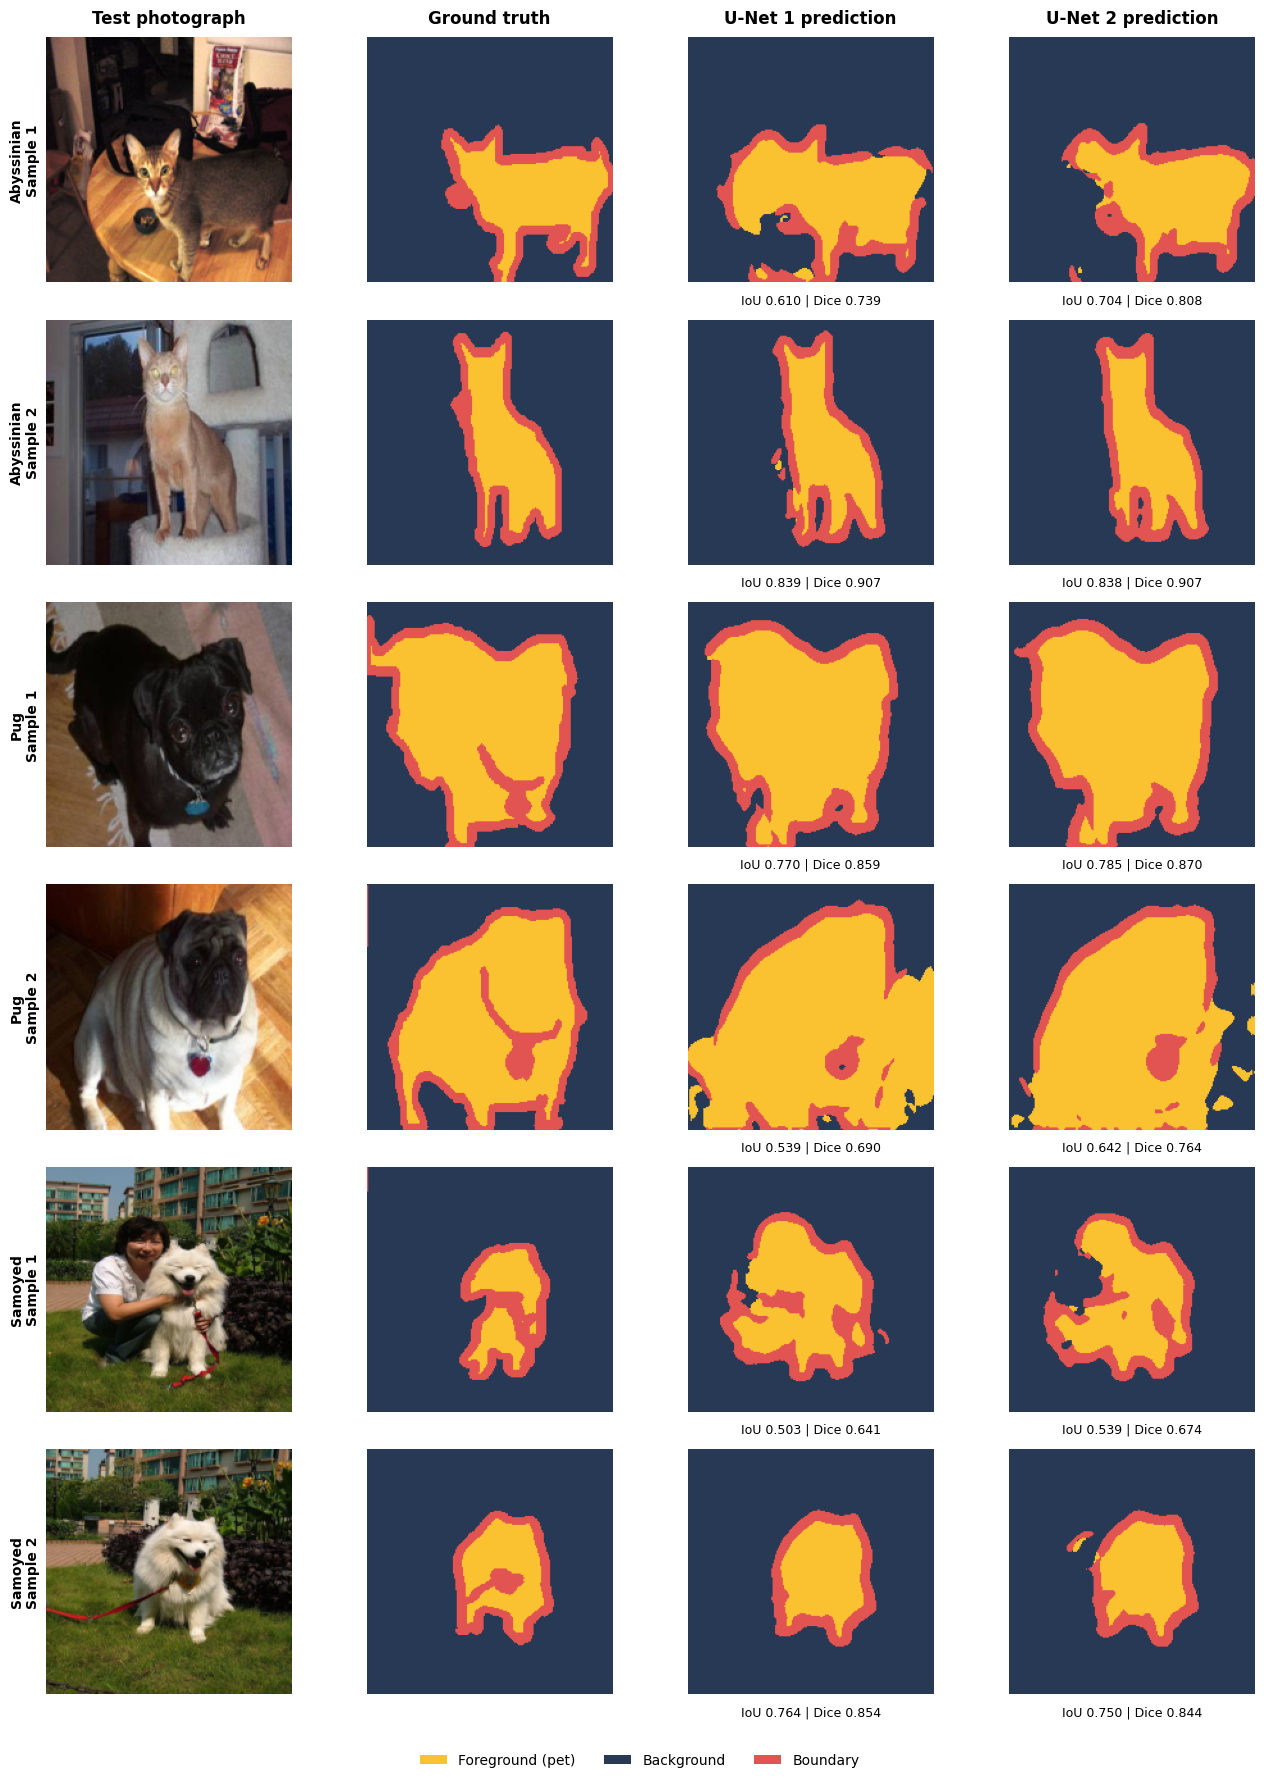

In [ ]:
# Display input, correct mask, and both outputs for all six test examples.
from matplotlib.patches import Patch

fig, axes = plt.subplots(6, 4, figsize=(13.5, 18.0))
column_titles = ['Test photograph', 'Ground truth',
                 'U-Net 1 prediction', 'U-Net 2 prediction']
for ax, title in zip(axes[0], column_titles):
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)

for row_id, (test_index, breed_name) in enumerate(selected_examples):
    image, target, _ = test_data[test_index]
    true_mask = target.numpy()
    axes[row_id, 0].imshow(image_for_display(image))
    axes[row_id, 1].imshow(mask_for_display(true_mask))

    for col_id, seed in enumerate(MODEL_SEEDS, start=2):
        model = models[seed]
        model.eval()
        with torch.inference_mode():
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                logits = model(image.unsqueeze(0).to(DEVICE))
            predicted = logits.argmax(dim=1).squeeze(0).cpu().numpy()
        image_confusion = np.bincount(
            (true_mask * NUM_CLASSES + predicted).ravel(),
            minlength=NUM_CLASSES ** 2
        ).reshape(NUM_CLASSES, NUM_CLASSES)
        image_scores = scores_from_confusion_matrix(image_confusion)
        axes[row_id, col_id].imshow(mask_for_display(predicted))
        axes[row_id, col_id].text(
            0.5, -0.045, f'IoU {image_scores["macro_iou"]:.3f} | '
            f'Dice {image_scores["macro_dice"]:.3f}',
            transform=axes[row_id, col_id].transAxes,
            ha='center', va='top', fontsize=9
        )

    axes[row_id, 0].set_ylabel(
        f'{breed_name}\nSample {row_id % 2 + 1}',
        fontsize=10, fontweight='bold'
    )
    for ax in axes[row_id]:
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

legend_items = [Patch(facecolor=MASK_COLORS[i] / 255.0, label=name)
                for i, name in enumerate(CLASS_NAMES)]
fig.legend(handles=legend_items, loc='lower center', ncol=3,
           bbox_to_anchor=(0.5, 0.008), frameon=False)
plt.tight_layout(rect=(0, 0.035, 1, 1), h_pad=1.1)
plt.savefig(OUTPUT_DIR / 'six_qualitative_test_examples.png',
            dpi=170, bbox_inches='tight')
plt.show()

## 11. Error analysis and interpretation

A per-class breakdown helps distinguish the easy, large regions from the more difficult thin boundary region. The row-normalized confusion matrices below show where the model tends to place pixels from each ground-truth class; a perfect model would have all its mass on the diagonal. The final printed discussion is generated from the scores actually measured in the previous cells.

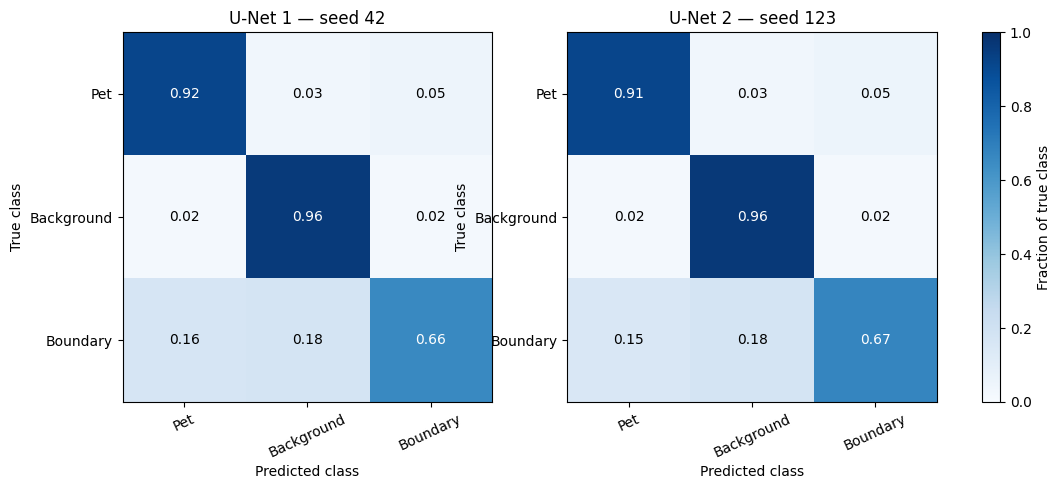

In [ ]:
# Each row totals approximately 100%: predicted class conditional on true class.
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
for ax, seed, label in zip(axes, MODEL_SEEDS, ['U-Net 1', 'U-Net 2']):
    cm = test_scores[seed]['confusion_matrix'].astype(np.float64)
    normalized = np.divide(cm, cm.sum(axis=1, keepdims=True),
                           out=np.zeros_like(cm), where=cm.sum(axis=1, keepdims=True) > 0)
    img = ax.imshow(normalized, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(NUM_CLASSES), labels=['Pet', 'Background', 'Boundary'], rotation=25)
    ax.set_yticks(range(NUM_CLASSES), labels=['Pet', 'Background', 'Boundary'])
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('True class')
    ax.set_title(f'{label} — seed {seed}')
    for r in range(NUM_CLASSES):
        for c in range(NUM_CLASSES):
            value = normalized[r, c]
            ax.text(c, r, f'{value:.2f}', ha='center', va='center',
                    color='white' if value > 0.55 else 'black')
fig.colorbar(img, ax=axes, fraction=0.035, pad=0.05, label='Fraction of true class')
plt.savefig(OUTPUT_DIR / 'test_confusion_matrices.png', dpi=170, bbox_inches='tight')
plt.show()

In [ ]:
# Produce a results paragraph from the genuine test scores rather than guessing outcomes.
first, second = MODEL_SEEDS
s1, s2 = test_scores[first], test_scores[second]
winning_seed = first if s1['macro_iou'] >= s2['macro_iou'] else second
winning_number = 1 if winning_seed == first else 2
winning_scores = test_scores[winning_seed]
difficulty_order = np.argsort(winning_scores['iou_per_class'])
hardest_class = CLASS_NAMES[difficulty_order[0]]

summary = (
    f'Both U-Net models were trained independently and evaluated on all '
    f'{len(test_data):,} official test images. U-Net 1 (seed {first}) achieved '
    f'a macro IoU of {s1["macro_iou"]:.4f} and macro Dice of '
    f'{s1["macro_dice"]:.4f}. U-Net 2 (seed {second}) achieved '
    f'a macro IoU of {s2["macro_iou"]:.4f} and macro Dice of '
    f'{s2["macro_dice"]:.4f}. The stronger run by macro IoU was U-Net '
    f'{winning_number}, with an absolute IoU difference of '
    f'{abs(s1["macro_iou"] - s2["macro_iou"]):.4f}. '
    f'The lowest IoU class in that run was {hardest_class.lower()} '
    f'({winning_scores["iou_per_class"][difficulty_order[0]]:.4f}). '
    'These numbers reflect a change in random initialization and stochastic training '
    'under otherwise matched settings; two seeds alone cannot establish '
    'statistically significant superiority. Finally, the class scores are '
    'macro-averaged from pixel counts over the entire test set, rather than '
    'averaging the six images selected for visualization.'
)
print('RESULTS AND DISCUSSION\n')
print(summary)
(OUTPUT_DIR / 'results_discussion.txt').write_text(summary + '\n', encoding='utf-8')

RESULTS AND DISCUSSION

Both U-Net models were trained independently and evaluated on all 3,669 official test images. U-Net 1 (seed 42) achieved a macro IoU of 0.7579 and macro Dice of 0.8524. U-Net 2 (seed 123) achieved a macro IoU of 0.7628 and macro Dice of 0.8557. The stronger run by macro IoU was U-Net 2, with an absolute IoU difference of 0.0049. The lowest IoU class in that run was boundary (0.5432). These numbers reflect a change in random initialization and stochastic training under otherwise matched settings; two seeds alone cannot establish statistically significant superiority. Finally, the class scores are macro-averaged from pixel counts over the entire test set, rather than averaging the six images selected for visualization.


727

## 12. CONFIRMING my Submission

In [ ]:
# Final checks: two trained models, three breed groups, six examples, full test coverage.
assert len(models) >= 2, 'Two trained networks are required.'
assert len(comparison) == 2, 'Comparison table must have two rows.'
assert comparison[['IOU', 'DICE']].notna().all().all()
assert ((comparison[['IOU', 'DICE']] >= 0) & (comparison[['IOU', 'DICE']] <= 1)).all().all()
assert all(test_scores[s]['num_images'] == len(test_data) for s in MODEL_SEEDS)
assert len(selected_examples) >= 6
assert len({breed for _, breed in selected_examples}) >= 3
assert len(per_image_results) == 2 * len(test_data)

# Save the configuration for reproducibility, alongside tables and graphics.
configuration = {
    'dataset': 'Oxford-IIIT Pet',
    'splits': {'train': len(train_data), 'validation': len(val_data),
               'official_test': len(test_data)},
    'seeds': list(MODEL_SEEDS),
    'segmentation_classes': list(CLASS_NAMES),
    'image_size': IMAGE_SIZE,
    'batch_size': BATCH_SIZE,
    'max_epochs': NUM_EPOCHS,
    'early_stopping_patience': EARLY_STOPPING_PATIENCE,
    'learning_rate': LEARNING_RATE,
    'weight_decay': WEIGHT_DECAY,
    'base_channels': BASE_CHANNELS,
    'best_epochs': {str(s): int(checkpoints[s]['epoch']) for s in MODEL_SEEDS},
    'metric_protocol': 'global test-set per-class pixel counts, then macro average',
}
(OUTPUT_DIR / 'experiment_configuration.json').write_text(
    json.dumps(configuration, indent=2), encoding='utf-8'
)

# Compress only compact result files. The large checkpoint weights remain in the output folder.
import zipfile
archive_path = Path('pet_segmentation_submission_results.zip')
with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for file_path in sorted(OUTPUT_DIR.iterdir()):
        if file_path.suffix.lower() != '.pt':
            archive.write(file_path, arcname=file_path.name)

print('LOOKING WHAT I NEEDED TO DO IN THE ASSIGNMENT AND RECONFIRMING CHECKLIST')
print('1. I did Two independently trained U-Net models with different seeds 42 and 123')
print('2. I did Explicit training, validation and test functions')
print('3. I did Qualitative results: 2 examples × 3 pet breeds')
print('4. I made all 3 segmentation regions retained and evaluated')
print(f'5. I compared as being told in the given instructional table IoU and Dice measured over all {len(test_data):,} official test images')
print('6. I did Per-image CSV, per-class CSV, full test results table and figures')
print(f'My Output folder: {OUTPUT_DIR.resolve()}')
print(f'My Supplementary results archive: {archive_path.resolve()}')

LOOKING WHAT I NEEDED TO DO IN THE ASSIGNMENT AND RECONFIRMING CHECKLIST
1. I did Two independently trained U-Net models with different seeds 42 and 123
2. I did Explicit training, validation and test functions
3. I did Qualitative results: 2 examples × 3 pet breeds
4. I made all 3 segmentation regions retained and evaluated
5. I compared as being told in the given instructional table IoU and Dice measured over all 3,669 official test images
6. I did Per-image CSV, per-class CSV, full test results table and figures
My Output folder: /content/pet_segmentation_results
My Supplementary results archive: /content/pet_segmentation_submission_results.zip


## References - These papers and youtube channel by Alladin helped me completing this assignment.

1. O. M. Parkhi, A. Vedaldi, A. Zisserman and C. V. Jawahar, "Cats and dogs," 2012 IEEE Conference on Computer Vision and Pattern Recognition, Providence, RI, USA, 2012, pp. 3498-3505, doi: 10.1109/CVPR.2012.6248092. keywords: {Positron emission tomography;Image segmentation;Cats;Dogs;Layout;Deformable models;Head},

2. University of Oxford Visual Geometry Group. *Oxford-IIIT Pet Dataset*. https://www.robots.ox.ac.uk/~vgg/data/pets/

3. PyTorch / Torchvision documentation. https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.OxfordIIITPet.html

4. Ronneberger, O., Fischer, P., and Brox, T. (2015). *U-Net: Convolutional Networks for Biomedical Image Segmentation*. https://arxiv.org/abs/1505.04597


**My Methodological note.** The dataset's trimap boundary is an ambiguous annotation region. This experiment retains it as a third supervised class to evaluate all three label values directly, rather than silently ignoring or merging it. A binary pet-vs-background study would be a different evaluation protocol and could produce different numbers.